# 03 · Modelo final v1 | CRISP-DM

**Conclusão:** a regressão foi construída, refinada, congelada e avaliada. Nesta versão, a regra histórica supera o ML no RMSE e permanece como método recomendado. O regressor é entregue com evidência completa, sem alegação de superioridade.

**Autoria:** Lucas Menghi, em desenvolvimento governado com assistência de agente e autorização humana. A solicitação de finalizar autorizou a conclusão técnica; não substitui aprovação comercial ou produtiva. Consulte [governança](docs/governance.md).

Este notebook lê os resultados congelados. Executá-lo novamente **não refaz seleção nem reabre novembro**. Os comandos originais de execução e as proteções estão em `scripts/finalize_model.py`.

| Etapa CRISP-DM | Entrega v1 |
|---|---|
| Entendimento do negócio | Variável resposta: valor bruto em £ de compras em 30 dias |
| Entendimento dos dados | Qualidade, zeros, extremos, população identificada |
| Preparação | 18 features em 90 dias; população e bordas verificadas |
| Modelagem | 23 configurações; cinco backtests temporais |
| Avaliação | Novembro após congelamento, baseline, segmentos e incerteza |
| Entrega | Artefato local e inferência batch testada; implantação produtiva não realizada |

## 1. Definição e critério mantidos

Preservamos a definição já trabalhada: transações positivas com identificação, sem prefixo de cancelamento, quantidade e preço positivos. Duplicatas e códigos especiais permanecem. Não descontamos devoluções futuras, nem apagamos retrospectivamente eventos das features.

Isso prevê **valor bruto registrado**, não receita líquida. A coincidência de vendas e cancelamentos exige outra definição se a pergunta comercial mudar; não mudamos a resposta durante a seleção para melhorar métricas.

As features usam `[t−90,t)`; a resposta usa `[t,t+30)`. Treino em março–outubro, com maturação das respostas antes de cada validação. O critério inicial é RMSE para previsão de valor esperado, acompanhado de MAE e viés. Uma melhora só em MAE não satisfaz o critério principal.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "reports/final").exists() else Path.cwd() / "Online Retail"
REPORT = ROOT / "reports/final"
selection = json.loads((REPORT / "selection.json").read_text(encoding="utf-8"))
evaluation = json.loads((REPORT / "evaluation.json").read_text(encoding="utf-8"))
ranking = pd.read_csv(REPORT / "tuning_ranking.csv")
folds = pd.read_csv(REPORT / "tuning_folds.csv")
holdout = pd.read_csv(REPORT / "holdout_metrics.csv")
segments = pd.read_csv(REPORT / "holdout_segments.csv")
calibration = pd.read_csv(REPORT / "holdout_calibration.csv")
importance = pd.read_csv(REPORT / "development_permutation_importance.csv")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
assert not selection["test_evaluated_at_freeze"]
assert not evaluation["model_changed_after_test"]
assert pd.Timestamp(selection["frozen_at_utc"]) < pd.Timestamp(evaluation["evaluated_at_utc"])
print("Configuração congelada:", selection["selected"])
print("Observações de treino:", selection["train_rows"])
print("Features:", len(selection["features"]))
print("Congelamento:", selection["frozen_at_utc"])
print("Avaliação:", evaluation["evaluated_at_utc"])

Configuração congelada: {'id': 'tweedie_log_p1.2_a0.1', 'family': 'tweedie', 'transform': 'signed_log1p', 'power': 1.2, 'alpha': 0.1}
Observações de treino: 15376
Features: 18
Congelamento: 2026-10-01T16:27:52.747418+00:00
Avaliação: 2026-10-01T16:28:21.122781+00:00


## 2. Refinamento e seleção no desenvolvimento

Ridge avalia regularização e transformação das features. Tweedie com `1 < power < 2` é candidato para zeros e valores positivos contínuos; seu link log produz média positiva. Transformamos as **features**, não a variável resposta, reduzindo o problema de extrapolação observado na primeira configuração.

Boosting compara perda quadrática com Poisson e duas complexidades. Usar perda Poisson para estimar uma média positiva não significa afirmar que valores em £ sejam contagens. Não há early stopping com split aleatório.

Os mesmos cinco folds e as mesmas linhas são usados para todos. As escalas são ajustadas no treino. Nenhum resultado de novembro orientou a seleção. Os 23 candidatos integram uma busca limitada e registrada; as métricas de desenvolvimento não são uma estimativa independente após seleção.

,candidate,rmse_gbp,mae_gbp,total_bias_pct
0,tweedie_log_p1.2_a0.1,"1,270.91",271.31,-11.34
1,tweedie_log_p1.2_a1,"1,274.35",271.94,-11.12
2,tweedie_log_p1.5_a0.1,"1,282.93",273.25,-12.85
3,tweedie_log_p1.2_a10,"1,284.12",273.15,-12.01
4,hgb_squared_error_l15_r10,"1,293.68",287.14,-12.49
5,hgb_squared_error_l7_r10,"1,295.30",285.96,-13.03
6,tweedie_log_p1.5_a1,"1,298.24",273.85,-14.24
7,hgb_squared_error_l7_r100,"1,298.56",281.83,-13.86
8,hgb_squared_error_l15_r100,"1,299.73",282.40,-13.50
9,ridge_raw_1000,"1,323.73",278.91,-8.43


,reference_date,train_n,n,rmse_gbp,mae_gbp,total_bias_pct
30,2011-06-01,5349,1959,"1,176.81",242.54,-10.98
31,2011-07-01,7308,1969,706.56,227.80,12.74
32,2011-08-01,9277,2025,"1,205.06",258.39,-0.68
33,2011-09-01,11302,1923,"1,822.78",310.24,-28.10
34,2011-10-01,13225,2151,"1,213.98",314.71,-17.83


No desenvolvimento, o regressor ficou 0.54% acima do RMSE da regra histórica.


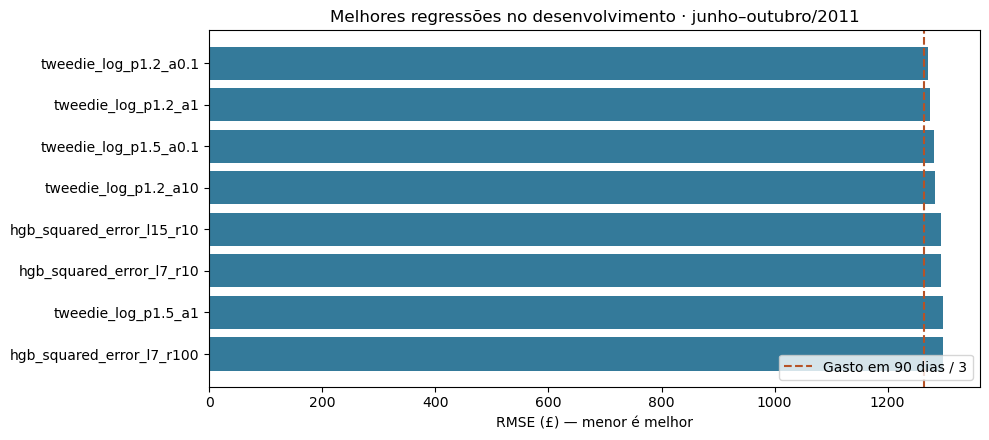

In [2]:
display(ranking[["candidate", "rmse_gbp", "mae_gbp", "total_bias_pct"]])
chosen = selection["selected"]["id"]
display(folds.loc[folds.candidate.eq(chosen), ["reference_date", "train_n", "n", "rmse_gbp", "mae_gbp", "total_bias_pct"]])
baseline_dev = pd.read_csv(ROOT / "reports/model_comparison.csv").set_index("model").loc["last_90d_div3", "rmse_gbp"]
regressor_dev = ranking.set_index("candidate").loc[chosen, "rmse_gbp"]
print(f"No desenvolvimento, o regressor ficou {100 * (regressor_dev / baseline_dev - 1):.2f}% acima do RMSE da regra histórica.")
fig, ax = plt.subplots(figsize=(10, 4.5))
top = ranking.head(8).iloc[::-1]
ax.barh(top.candidate, top.rmse_gbp, color="#347a9a")
ax.axvline(baseline_dev, color="#b65327", linestyle="--", label="Gasto em 90 dias / 3")
ax.set(xlabel="RMSE (£) — menor é melhor", title="Melhores regressões no desenvolvimento · junho–outubro/2011")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## 3. Avaliação final em novembro

A configuração foi congelada no commit `b723a39` antes de calcular a resposta de novembro. O artefato final usa 15.376 observações cliente/referência do desenvolvimento. Não foi retreinado com novembro após a avaliação.

Referência: **01/11/2011**; resposta: **[01/11/2011, 01/12/2011)**. Comparação com a mesma população e o mesmo horizonte. Os resultados são de um mês sazonal, não de um ano independente.

,model,n,rmse_gbp,mae_gbp,bias_gbp,observed_total_gbp,predicted_total_gbp,total_bias_pct
0,tweedie_log_p1.2_a0.1,2461,"1,127.79",316.77,-58.71,"884,548.10","740,072.92",-16.33
1,last_90d_div3,2461,927.77,326.20,-7.62,"884,548.10","865,805.21",-2.12


Clientes: 2,461; sem recompra: 57.09%
Piora de RMSE da regressão: 21.56%
Redução de MAE: 2.89%


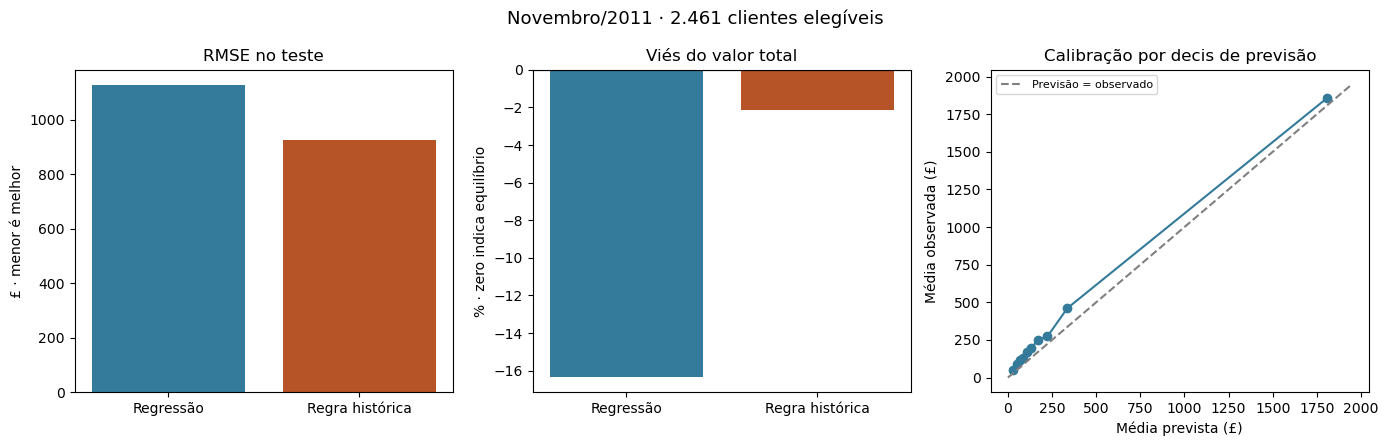

In [3]:
display(holdout)
print(f"Clientes: {evaluation['customers']:,}; sem recompra: {evaluation['zero_response_pct']:.2f}%")
regression_row, baseline_row = holdout.iloc[0], holdout.iloc[1]
print(f"Piora de RMSE da regressão: {100 * (regression_row.rmse_gbp / baseline_row.rmse_gbp - 1):.2f}%")
print(f"Redução de MAE: {100 * (1 - regression_row.mae_gbp / baseline_row.mae_gbp):.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
labels = ["Regressão", "Regra histórica"]
colors = ["#347a9a", "#b65327"]
axes[0].bar(labels, holdout.rmse_gbp, color=colors)
axes[0].set(title="RMSE no teste", ylabel="£ · menor é melhor")
axes[1].bar(labels, holdout.total_bias_pct, color=colors)
axes[1].axhline(0, color="black", linewidth=.8)
axes[1].set(title="Viés do valor total", ylabel="% · zero indica equilíbrio")
axes[2].plot(calibration.prediction_mean_gbp, calibration.observed_mean_gbp, "o-", color=colors[0])
limit = max(calibration.prediction_mean_gbp.max(), calibration.observed_mean_gbp.max()) * 1.05
axes[2].plot([0, limit], [0, limit], "--", color="gray", label="Previsão = observado")
axes[2].set(title="Calibração por decis de previsão", xlabel="Média prevista (£)", ylabel="Média observada (£)")
axes[2].legend(fontsize=8)
fig.suptitle("Novembro/2011 · 2.461 clientes elegíveis", fontsize=13)
fig.tight_layout()
(ROOT / "reports/figures").mkdir(exist_ok=True)
fig.savefig(ROOT / "reports/figures/final_evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

### Leitura do resultado

A regressão tem **RMSE 21,56% maior**, embora reduza MAE em 2,89%. Ela subestima o total em 16,33%, contra 2,12% da regra. A menor média de erros absolutos não compensa os erros maiores quando o objetivo é estimar valor esperado.

**Decisão:** preservar a regressão como modelo desenvolvido e avaliado; manter a regra histórica como recomendação v1. Nenhum parâmetro foi alterado para corrigir novembro. A conclusão desfavorável é parte do resultado técnico.

## 4. Onde o modelo erra e qual é a incerteza?

Segmentos por resposta zero/positiva são diagnósticos retrospectivos, não disponíveis no momento da decisão. Faixas de gasto histórico são conhecidas antes da referência. Interpretar ambos evita confundir bom desempenho em clientes sem recompra com boa estimativa de receita.

In [4]:
display(segments)
ci = evaluation["paired_customer_bootstrap"]["ci95_percentile"]
print(f"IC percentil 95% para RMSE regressão − regra: £{ci[0]:.2f} a £{ci[1]:.2f}")
print("Bootstrap pareado por cliente, 2.000 reamostragens; mesma previsão e modelo fixos.")
print("Não quantifica incerteza de outros meses, da seleção, do treino ou de dependência não observada entre clientes.")

,model,dimension,segment,n,rmse_gbp,mae_gbp,bias_gbp,observed_total_gbp,predicted_total_gbp,total_bias_pct
0,regressor,repurchase,positive,1056,"1,701.33",546.88,-328.17,"884,548.10","538,001.02",-39.18
1,last_90d_div3,repurchase,positive,1056,"1,366.77",499.27,-278.70,"884,548.10","590,240.98",-33.27
2,regressor,repurchase,zero,1405,228.76,143.82,143.82,0.00,"202,071.90",NaN
3,last_90d_div3,repurchase,zero,1405,321.98,196.13,196.13,0.00,"275,564.23",NaN
4,regressor,historical_spend,500_to_2000,976,551.01,328.06,-89.53,"326,009.27","238,631.51",-26.80
5,last_90d_div3,historical_spend,500_to_2000,976,548.97,348.07,-16.49,"326,009.27","309,919.61",-4.94
6,regressor,historical_spend,above_2000,187,"3,839.96","1,492.97",5.25,"405,472.08","406,453.02",0.24
7,last_90d_div3,historical_spend,above_2000,187,"3,059.11","1,476.29",185.45,"405,472.08","440,151.67",8.55
8,regressor,historical_spend,up_to_500,1298,242.72,138.83,-44.74,"153,066.75","94,988.39",-37.94
9,last_90d_div3,historical_spend,up_to_500,1298,239.14,144.07,-28.76,"153,066.75","115,733.93",-24.39


IC percentil 95% para RMSE regressão − regra: £11.64 a £386.29
Bootstrap pareado por cliente, 2.000 reamostragens; mesma previsão e modelo fixos.
Não quantifica incerteza de outros meses, da seleção, do treino ou de dependência não observada entre clientes.


Os dois limites da diferença de RMSE são positivos neste bootstrap, favorecendo a regra neste mês. Isso não prova que a regra sempre vencerá.

A regressão melhora RMSE em clientes sem recompra, mas piora em quem compra. No grupo de gasto histórico acima de £2.000, seu total é próximo do observado, porém os erros individuais são maiores: compensação entre superestimação e subestimação pode esconder problemas.

## 5. Interpretação do regressor

Importância por permutação no último fold de **desenvolvimento**, com cinco repetições. O modelo usado nessa análise foi treinado antes de outubro; a importância não usa o teste final.

As janelas de gasto e ticket são correlacionadas. Permutar uma feature isolada pode criar combinações irreais, como ticket incompatível com gasto e número de pedidos. A magnitude não deve ser interpretada como efeito causal nem participação percentual na receita.

,feature,increase_mse_gbp2,std_gbp2
0,ticket_60d,"29,770,544.84","15,486,670.08"
1,spend_90d,"2,235,818.69","169,671.34"
2,ticket_90d,"1,376,877.52","429,271.35"
3,spend_60d,"1,370,084.11","69,951.56"
4,recency_days,"1,067,171.77","203,603.17"
5,units_90d,"929,798.03","118,376.43"
6,orders_60d,"793,477.59","69,834.48"
7,products_30d,"641,280.74","182,970.90"
8,units_60d,"620,854.17","178,194.52"
9,units_30d,"438,533.04","189,664.88"


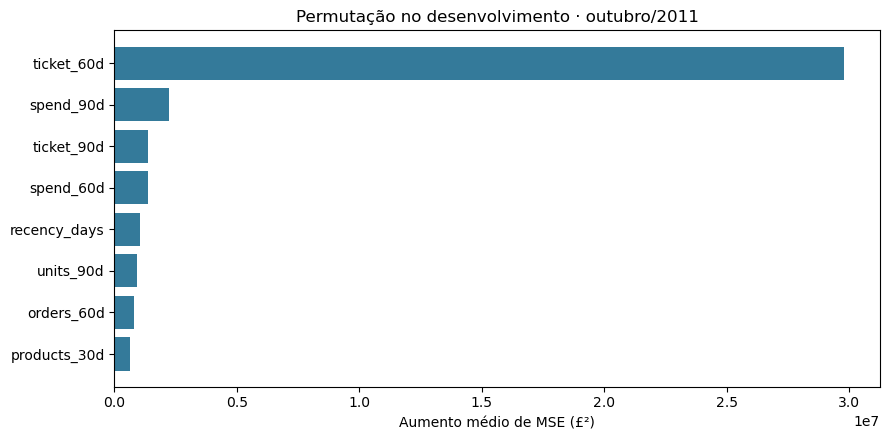

In [5]:
display(importance)
fig, ax = plt.subplots(figsize=(9, 4.5))
top = importance.head(8).iloc[::-1]
ax.barh(top.feature, top.increase_mse_gbp2, color="#347a9a")
ax.set(title="Permutação no desenvolvimento · outubro/2011", xlabel="Aumento médio de MSE (£²)")
fig.tight_layout()
plt.show()

## 6. Artefato, previsão e verificação

- `artifacts/retail_v1.joblib`: pipeline avaliado, mantido localmente.
- `reports/final/selection.json`: parâmetros, features, dados, código e ambiente.
- `reports/final/artifact_manifest.json`: hash do artefato original.
- `scripts/rebuild_artifact.py`: reconstrói a mesma configuração com base de treino equivalente; não retuna.
- `scripts/predict.py`: previsão sem exigir os 30 dias futuros.

```powershell
python scripts/predict.py --as-of 2011-11-01 --output reports/predictions/november.csv
```

Saída: `regressor_prediction_gbp`, `baseline_prediction_gbp` e `prediction_gbp`, que identifica a regra recomendada. A escolha é explícita em `recommended_method`. O CSV de previsões individuais fica fora do Git.

Nove testes passaram: bordas, população, zeros, maturação, invariância a eventos futuros, paridade de features, validação numérica e serialização. A execução batch reproduziu a avaliação nos 2.461 clientes. O estimador foi reconstruído com os parâmetros congelados e reproduziu as previsões de treino; o artefato original foi preservado.

Não foram testados serviço produtivo, concorrência, SLO ou disponibilidade real da fonte. Consulte o [contrato batch](docs/batch_contract.md).

## 7. Encerramento da versão

**Concluído:** definição consistente, exploração, preparação, regressão refinada, avaliação posterior ao congelamento, artefato, inferência, testes e rastreabilidade.

**Não demonstrado:** ganho do ML sobre a regra no critério principal, generalização anual, impacto comercial ou prontidão produtiva.

Lucas autorizou a finalização técnica; a adequação comercial das regras e a implantação exigem revisão específica. Novembro já foi observado. Uma próxima versão precisa declarar essa reutilização e obter outra avaliação independente para uma nova alegação de desempenho.

Referências: [model card](docs/model_card.md), [protocolo congelado](docs/finalization_protocol.md), [TweedieRegressor](https://scikit-learn.org/1.2/modules/generated/sklearn.linear_model.TweedieRegressor.html), [fonte UCI](https://doi.org/10.24432/C5BW33).